# 01 — Khám phá dữ liệu Customer Churn

## Mục tiêu
- Hiểu cấu trúc và chất lượng dữ liệu.
- Kiểm tra giá trị thiếu, dữ liệu trùng lặp và kiểu dữ liệu.
- Kiểm tra phân bố nhãn Churn.
- Chia dữ liệu train/test có stratify.
- Phân tích các đặc trưng trên tập train.
- Đề xuất các bước tiền xử lý và Feature Engineering.

Tập test được giữ riêng để đánh giá cuối cùng.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

### data direction

In [2]:
current_dir = Path.cwd()

if (current_dir / "data" / "raw").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Not found folder data/raw.")

csv_files = sorted((PROJECT_ROOT / "data" / "raw").glob("*.csv"))

print("CSV files:")
for path in csv_files:
    print(path.name)

CSV files:
WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df_raw = pd.read_csv(DATA_PATH)

# Làm việc trên bản sao, giữ dữ liệu vừa đọc để đối chiếu.
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### data structure and missing values


In [4]:
df.info()
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
text_columns = df.select_dtypes(include=["object", "string"]).columns

blank_counts = pd.Series(0, index=df.columns, dtype="int64")

for column in text_columns:
    blank_counts[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
    )

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "blank_count": blank_counts,
})

display(
    missing_summary.sort_values(
        ["missing_count", "blank_count"],
        ascending=False,
    )
)

,missing_count,blank_count
TotalCharges,0,11
customerID,0,0
gender,0,0
SeniorCitizen,0,0
Partner,0,0
Dependents,0,0
tenure,0,0
PhoneService,0,0
MultipleLines,0,0
InternetService,0,0


In [6]:
for column in text_columns:
    df[column] = df[column].str.strip().replace("", np.nan)

### check duplicate and customers id

In [7]:
print("duplicated rows:", df.duplicated().sum())
print("customerID missing:", df["customerID"].isna().sum())
print("customerID duplicated:", df["customerID"].duplicated().sum())

duplicated rows: 0
customerID missing: 0
customerID duplicated: 0


### change TotalCharges into numeric

In [8]:
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce",
)

invalid_total_charges = (
    df["TotalCharges"].notna()
    & total_charges_numeric.isna()
)

print(
    "Số giá trị TotalCharges không hợp lệ:",
    invalid_total_charges.sum(),
)

display(
    df.loc[
        invalid_total_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"],
    ]
)

Số giá trị TotalCharges không hợp lệ: 0


,customerID,tenure,MonthlyCharges,TotalCharges


In [10]:
df["TotalCharges"] = total_charges_numeric

display(
    df.loc[
        df["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"],
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [11]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

display(df[numeric_columns].describe().T)

print("Số giá trị âm:")
display(df[numeric_columns].lt(0).sum())

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


Số giá trị âm:


tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64

In [12]:
categorical_columns = [
    column
    for column in df.columns
    if column not in numeric_columns + ["customerID"]
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False).to_string())


gender:
gender
Male      3555
Female    3488

SeniorCitizen:
SeniorCitizen
0    5901
1    1142

Partner:
Partner
No     3641
Yes    3402

Dependents:
Dependents
No     4933
Yes    2110

PhoneService:
PhoneService
Yes    6361
No      682

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526

OnlineBackup:
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526

DeviceProtection:
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526

TechSupport:
TechSupport
No                     3473
Yes                    2044
No internet service    1526

StreamingTV:
StreamingTV
No                     2810
Yes                    2707
No internet service    

### check and encoding Churn

In [13]:
print(df["Churn"].value_counts(dropna=False))

if df["Churn"].isna().any():
    raise ValueError("Churn has missing values, check before countinue.")

unexpected_labels = set(df["Churn"].unique()) - {"Yes", "No"}

if unexpected_labels:
    raise ValueError(f"Churn is unacceptabled: {unexpected_labels}")

df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1,
})

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [14]:
label_summary = (
    df["Churn"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename("count")
    .to_frame()
)

label_summary["percentage"] = (
    label_summary["count"] / len(df) * 100
)

display(label_summary)

,count,percentage
Churn,,
0,5174,73.463013
1,1869,26.536987


### Split Train/Test

In [16]:
if df["customerID"].isna().any() or df["customerID"].duplicated().any():
    raise ValueError(
        "Cần giải quyết customerID thiếu hoặc trùng trước khi chia dữ liệu."
    )

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["Churn"],
)

train_df = train_df.copy()
test_df = test_df.copy()

print("Train:", train_df.shape)
print("Test:", test_df.shape)

split_summary = pd.DataFrame({
    "train": train_df["Churn"].value_counts(normalize=True),
    "test": test_df["Churn"].value_counts(normalize=True),
}).sort_index()

display(split_summary)

Train: (5634, 21)
Test: (1409, 21)


,train,test
Churn,,
0,0.734647,0.734564
1,0.265353,0.265436


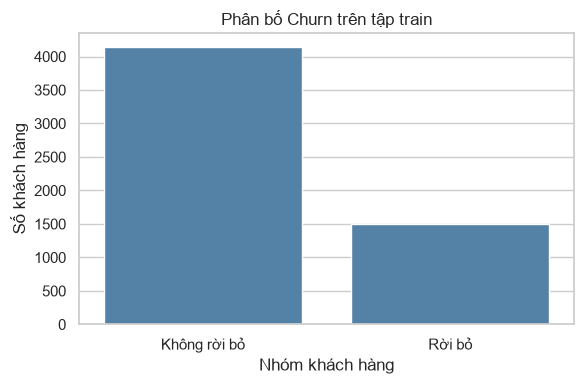

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))

sns.countplot(
    data=train_df,
    x="Churn",
    order=[0, 1],
    color="steelblue",
    ax=ax,
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Không rời bỏ", "Rời bỏ"])
ax.set_title("Phân bố Churn trên tập train")
ax.set_xlabel("Nhóm khách hàng")
ax.set_ylabel("Số khách hàng")

plt.tight_layout()
plt.show()

### Analyzing numerical features

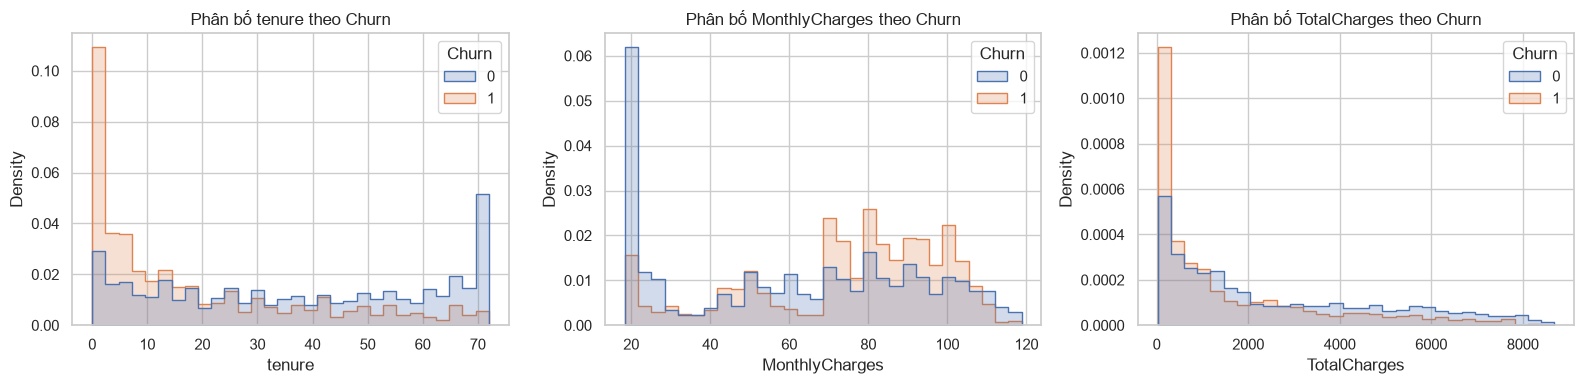

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, numeric_columns):
    sns.histplot(
        data=train_df,
        x=column,
        hue="Churn",
        bins=30,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax,
    )
    ax.set_title(f"Phân bố {column} theo Churn")

plt.tight_layout()
plt.show()

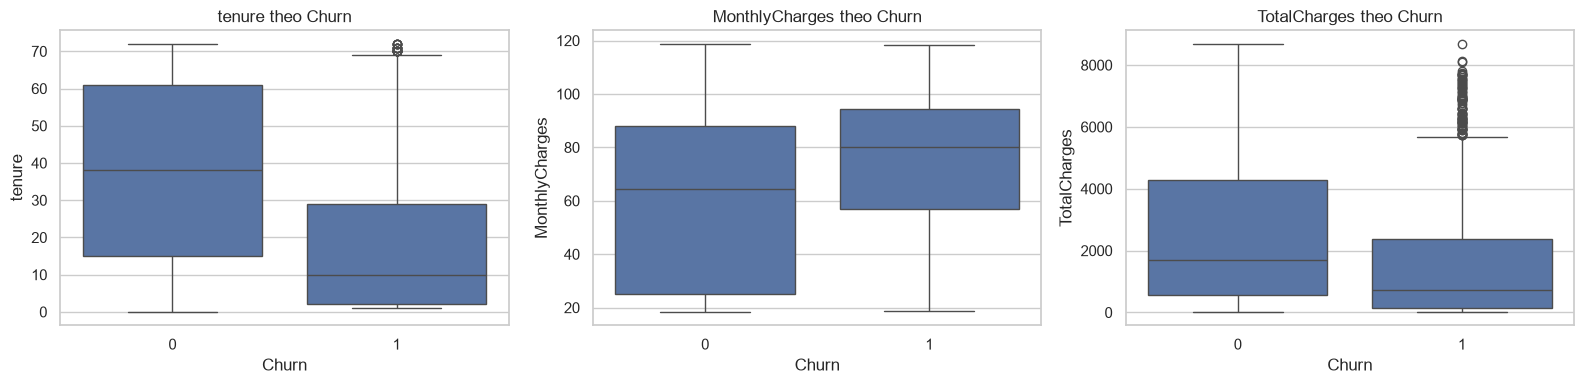

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(
        data=train_df,
        x="Churn",
        y=column,
        ax=ax,
    )
    ax.set_title(f"{column} theo Churn")

plt.tight_layout()
plt.show()

### Analyzing categorical features

,customer_count,churn_rate
Contract,,
Month-to-month,3102,0.427466
One year,1173,0.110827
Two year,1359,0.028698


,customer_count,churn_rate
InternetService,,
Fiber optic,2483,0.420862
DSL,1937,0.186887
No,1214,0.072488


,customer_count,churn_rate
PaymentMethod,,
Electronic check,1891,0.457430
Mailed check,1286,0.192846
Bank transfer (automatic),1244,0.161576
Credit card (automatic),1213,0.149217


,customer_count,churn_rate
TechSupport,,
No,2771,0.417539
Yes,1649,0.151607
No internet service,1214,0.072488


,customer_count,churn_rate
OnlineSecurity,,
No,2797,0.419378
Yes,1623,0.144177
No internet service,1214,0.072488


,customer_count,churn_rate
SeniorCitizen,,
1,920,0.410870
0,4714,0.236954


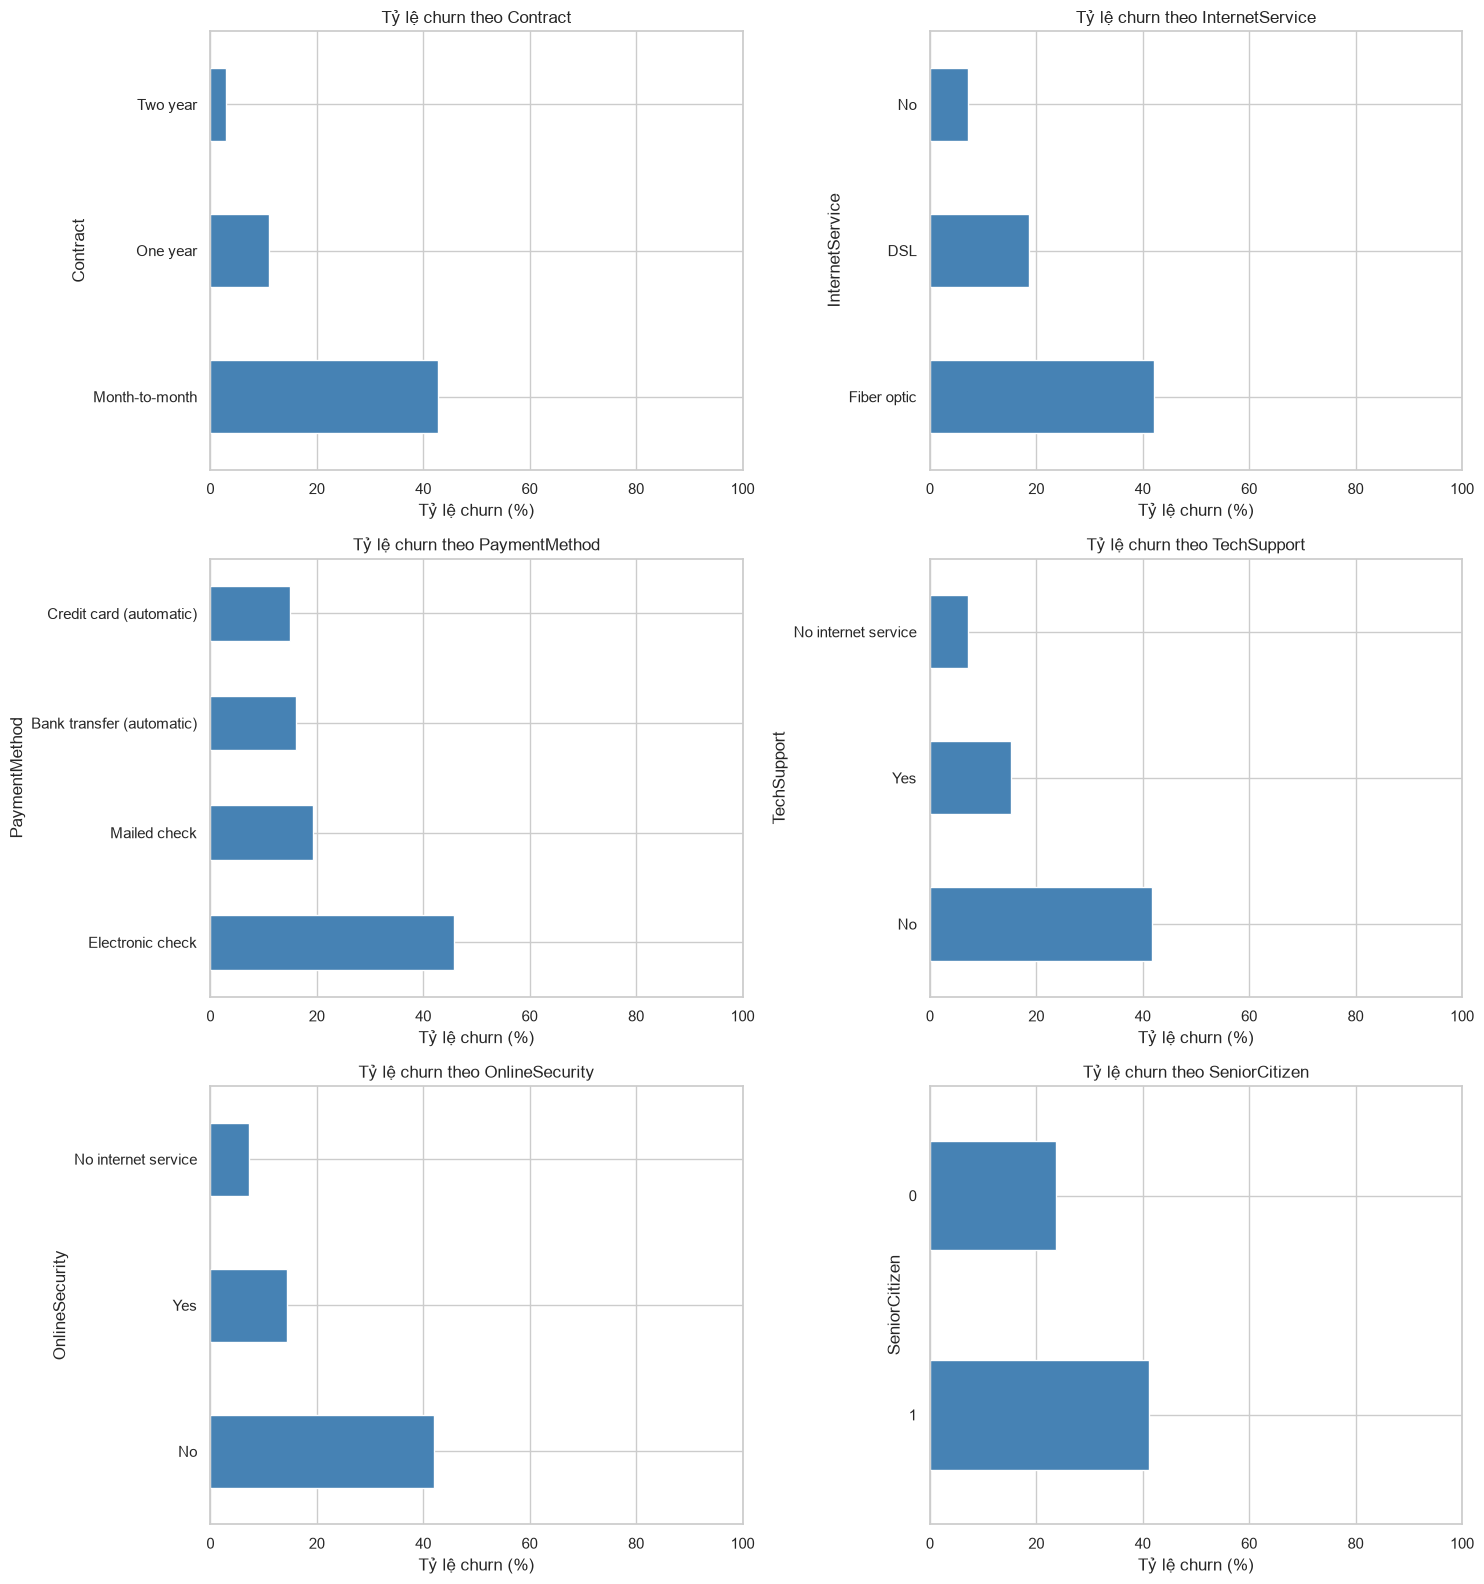

In [20]:
selected_categories = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "SeniorCitizen",
]

fig, axes = plt.subplots(3, 2, figsize=(15, 16))

for ax, column in zip(axes.flat, selected_categories):
    summary = (
        train_df.groupby(column, observed=True)["Churn"]
        .agg(customer_count="size", churn_rate="mean")
        .sort_values("churn_rate", ascending=False)
    )

    display(summary)

    (summary["churn_rate"] * 100).plot.barh(
        ax=ax,
        color="steelblue",
    )

    ax.set_title(f"Tỷ lệ churn theo {column}")
    ax.set_xlabel("Tỷ lệ churn (%)")
    ax.set_ylabel(column)
    ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

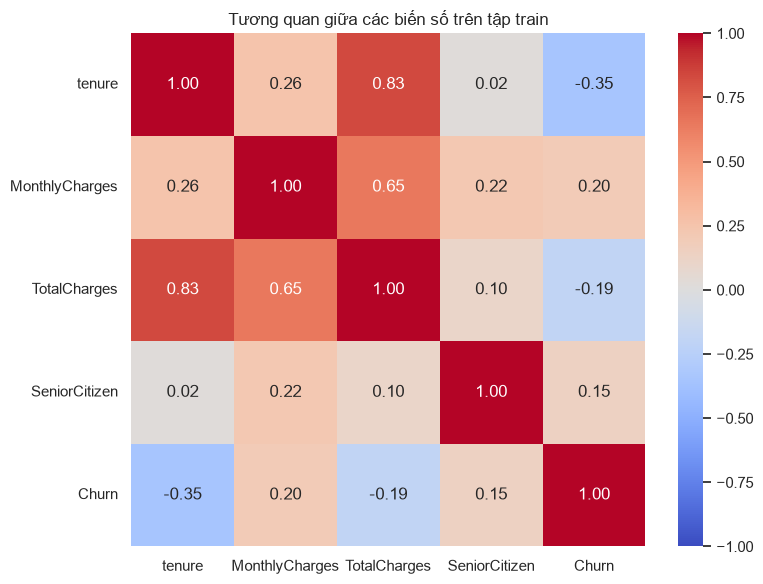

In [21]:
correlation_columns = numeric_columns + ["SeniorCitizen", "Churn"]

correlation = train_df[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Tương quan giữa các biến số trên tập train")
plt.tight_layout()
plt.show()

In [22]:
split_dir = PROJECT_ROOT / "data" / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

train_df[["customerID"]].to_csv(
    split_dir / "train_ids.csv",
    index=False,
)

test_df[["customerID"]].to_csv(
    split_dir / "test_ids.csv",
    index=False,
)

## Kết luận EDA

### 1. Cấu trúc và chất lượng dữ liệu

- Dataset gồm 7.043 khách hàng và 21 cột, bao gồm mã khách hàng,
  19 đặc trưng đầu vào và nhãn mục tiêu Churn.
- Không phát hiện dòng trùng lặp, customerID bị thiếu hoặc customerID trùng.
- Không phát hiện giá trị âm trong tenure, MonthlyCharges và TotalCharges.
- tenure nằm trong khoảng 0–72 tháng; MonthlyCharges nằm trong khoảng
  18,25–118,75; TotalCharges hợp lệ nằm trong khoảng 18,80–8.684,80.

Cột TotalCharges ban đầu có kiểu chuỗi và chứa 11 giá trị chỉ gồm
khoảng trắng. Các giá trị này đã được chuyển thành giá trị thiếu,
sau đó cột được chuyển sang dạng số. Ngoài 11 trường hợp trên,
không phát hiện giá trị không thể chuyển thành số.

Cả 11 khách hàng thiếu TotalCharges đều có tenure = 0. Điều này
gợi ý dữ liệu thiếu có liên quan đến khách hàng mới bắt đầu sử dụng
dịch vụ, nhưng chưa đủ cơ sở để mặc định thay tất cả bằng 0.

Các giá trị "No internet service" và "No phone service" thể hiện
tình trạng sử dụng dịch vụ, không phải giá trị thiếu.

### 2. Phân bố nhãn và cách chia dữ liệu

Trên toàn bộ dataset:
- Không rời bỏ (Churn = 0): 5.174 khách hàng, chiếm 73,46%.
- Rời bỏ (Churn = 1): 1.869 khách hàng, chiếm 26,54%.

Dữ liệu có sự mất cân bằng giữa hai lớp. Vì vậy, Accuracy không nên
là chỉ số đánh giá duy nhất; cần xem thêm Precision, Recall, F1-score,
ROC-AUC và Confusion Matrix.

Dữ liệu đã được chia theo tỷ lệ 80/20, sử dụng stratify theo Churn
và random_state = 42:
- Train: 5.634 khách hàng.
- Test: 1.409 khách hàng.

Tỷ lệ churn của train và test đều xấp xỉ 26,54%, cho thấy việc chia
stratify đã giữ được phân bố nhãn.

Các phân tích sâu được thực hiện trên tập train. Danh sách customerID
của hai tập đã được lưu để các thực nghiệm sau dùng cùng cách chia.
Tập test được giữ riêng cho đánh giá cuối cùng.

### 3. Mối liên hệ giữa các đặc trưng số và churn

Từ histogram, boxplot và ma trận tương quan trên tập train:

- Khách hàng rời bỏ có xu hướng sử dụng dịch vụ trong thời gian
  ngắn hơn. tenure có tương quan âm với Churn, khoảng -0,35.
- Nhóm rời bỏ có phân bố MonthlyCharges nghiêng về mức phí cao hơn.
  MonthlyCharges có tương quan dương với Churn, khoảng 0,20.
- Nhóm rời bỏ có xu hướng có TotalCharges thấp hơn.
  Tương quan giữa TotalCharges và Churn khoảng -0,19.
- tenure và TotalCharges có tương quan dương cao, khoảng 0,83.
  Do đó, hai đặc trưng này chứa một phần thông tin liên quan nhau.
- MonthlyCharges và TotalCharges có tương quan dương khoảng 0,65.

Một số điểm nằm ngoài râu boxplot chưa thể xem là dữ liệu sai.
Không loại bỏ các điểm này chỉ dựa trên boxplot.

### 4. Mối liên hệ giữa các đặc trưng phân loại và churn

Các tỷ lệ dưới đây được tính trên tập train.

#### Loại hợp đồng

| Loại hợp đồng | Số khách hàng | Tỷ lệ churn |
|---|---:|---:|
| Month-to-month | 3.102 | 42,75% |
| One year | 1.173 | 11,08% |
| Two year | 1.359 | 2,87% |

Nhóm hợp đồng theo tháng có tỷ lệ churn cao hơn rõ rệt so với
hai nhóm hợp đồng dài hạn. Contract là đặc trưng đáng chú ý
trong các thực nghiệm tiếp theo.

#### Dịch vụ Internet

| Dịch vụ | Số khách hàng | Tỷ lệ churn |
|---|---:|---:|
| Fiber optic | 2.483 | 42,09% |
| DSL | 1.937 | 18,69% |
| Không sử dụng Internet | 1.214 | 7,25% |

Nhóm Fiber optic có tỷ lệ churn cao nhất trong ba nhóm.
Cần xem xét thêm các yếu tố liên quan như mức phí và loại hợp đồng
trước khi đưa ra diễn giải kinh doanh.

#### Phương thức thanh toán

| Phương thức | Số khách hàng | Tỷ lệ churn |
|---|---:|---:|
| Electronic check | 1.891 | 45,74% |
| Mailed check | 1.286 | 19,28% |
| Bank transfer (automatic) | 1.244 | 16,16% |
| Credit card (automatic) | 1.213 | 14,92% |

Nhóm Electronic check có tỷ lệ churn cao hơn các nhóm còn lại.

#### Hỗ trợ kỹ thuật và bảo mật

- Với TechSupport, nhóm "No" có tỷ lệ churn 41,75%,
  trong khi nhóm "Yes" có tỷ lệ 15,16%.
- Với OnlineSecurity, nhóm "No" có tỷ lệ churn 41,94%,
  trong khi nhóm "Yes" có tỷ lệ 14,42%.
- Nhóm không sử dụng Internet có tỷ lệ churn 7,25%.

Cần phân biệt khách hàng có Internet nhưng không đăng ký dịch vụ
bổ sung với khách hàng không sử dụng Internet.

#### Người cao tuổi

- SeniorCitizen = 1: 920 khách hàng, tỷ lệ churn 41,09%.
- SeniorCitizen = 0: 4.714 khách hàng, tỷ lệ churn 23,70%.

Trong tập train, nhóm người cao tuổi có tỷ lệ churn cao hơn.

Các kết quả trên thể hiện mối liên hệ quan sát từ dữ liệu,
không chứng minh quan hệ nhân quả và chưa xác định được tầm quan
trọng của từng đặc trưng trong mô hình.

### 5. Quyết định tiền xử lý cho giai đoạn tiếp theo

- Giữ customerID để đối chiếu dữ liệu và tái tạo train/test,
  nhưng loại khỏi đầu vào mô hình.
- Sử dụng Churn đã mã hóa: No = 0, Yes = 1.
- Xử lý giá trị thiếu của TotalCharges trong pipeline.
  Có thể dùng median làm phương án baseline và cân nhắc thêm
  cờ đánh dấu giá trị thiếu.
- One-Hot Encoding cho các biến phân loại.
- SeniorCitizen là biến nhị phân dù được lưu dưới dạng số;
  có thể giữ nguyên mã 0/1.
- Chuẩn hóa biến số cho Logistic Regression.
  Các mô hình cây không bắt buộc chuẩn hóa.
- Fit các bước tiền xử lý chỉ trên phần huấn luyện của mỗi fold
  khi cross-validation.
- Nếu thử SMOTE, chỉ áp dụng trên phần huấn luyện của từng fold.

### 6. Hướng Feature Engineering cần kiểm chứng

Từ các quan sát EDA, đề xuất thử nghiệm:
- Nhóm thời gian sử dụng dịch vụ.
- Tổng số dịch vụ khách hàng đăng ký.
- Đặc trưng kết hợp Contract và tenure.
- Đặc trưng kết hợp MonthlyCharges và InternetService.
- Cờ đánh dấu khách hàng mới hoặc TotalCharges bị thiếu.

Đây là các giả thuyết cần kiểm chứng bằng thực nghiệm.
Chưa thể kết luận chúng cải thiện mô hình trước khi so sánh
kết quả cross-validation với baseline.

### 7. Định hướng thực nghiệm

- So sánh Logistic Regression, Decision Tree, Random Forest và XGBoost.
- Sử dụng cùng các fold Stratified Cross-Validation trên tập train.
- So sánh trước và sau Feature Engineering, tuning và xử lý
  mất cân bằng dữ liệu.
- Chọn cấu hình dựa trên kết quả cross-validation.
- Huấn luyện lại cấu hình đã chọn trên toàn bộ tập train,
  sau đó đánh giá cuối cùng trên tập test.